# Phase 2: Comment Type Categorization

**Course Project — Sentiment Analysis on Racism Against Indians/Asians**

---

## Objective
Categorize each tweet into a **specific type of racist discourse** (or positive counter-discourse) using keyword-based NLP classification.

This builds on Phase 1's sentiment labels to add a deeper layer — not just *whether* a comment is negative, but *what kind* of negativity it represents.

## 2.1 Setup & Load Phase 1 Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

df = pd.read_csv('data/phase1_sentiment.csv')
print(f"Loaded {len(df)} tweets with sentiment labels")
print(f"\nSentiment distribution:")
print(df['sentiment_label'].value_counts())
df.head()

Loaded 500 tweets with sentiment labels

Sentiment distribution:
sentiment_label
positive    229
negative    142
neutral     129
Name: count, dtype: int64


,id,platform,date,username,text,cleaned_text,target_group,likes,retweets,replies,vader_negative,vader_neutral,vader_positive,vader_compound,sentiment_label
0,1,twitter,2026-03-22,user_anon_0001,Community in Charlotte rallied around the vand...,Community in Charlotte rallied around the vand...,Asian,24418,4790,2639,0.222,0.778,0.000,-0.6124,negative
1,2,twitter,2026-02-08,user_anon_0002,'Do you worship cows?' asked my 15-year-old's ...,'Do you worship cows?' asked my 15-year-old's ...,Indian,2439,1204,295,0.000,0.726,0.274,0.5994,positive
2,3,twitter,2025-10-28,user_anon_0003,Building manager in Arlington sent a memo targ...,Building manager in Arlington sent a memo targ...,Indian,2298,404,353,0.000,1.000,0.000,0.0000,neutral
3,4,twitter,2026-02-27,user_anon_0004,'China flu' 'Indian variant' — racializing dis...,'China flu' 'Indian variant' — racializing dis...,Asian/Indian,12892,1733,1468,0.372,0.628,0.000,-0.7964,negative
4,5,twitter,2025-12-27,user_anon_0005,Our school in Pittsburgh launched an anti-raci...,Our school in Pittsburgh launched an anti-raci...,Asian,6783,3397,754,0.198,0.446,0.356,0.2942,positive


## 2.2 Define Comment Type Taxonomy

We define **16 categories** organized into negative, positive, and neutral types:

### Negative Categories
| Category | Key Patterns |
|---|---|
| Microaggression | "where are you from", "surprisingly good" |
| Stereotyping | "all Asians", "good at math", "nerdy" |
| Xenophobia | "go back", "go home", "taking jobs" |
| Verbal Abuse | Direct slurs and insults |
| Workplace Discrimination | "passed over", "bamboo ceiling" |
| Cultural Intolerance | "smell", "weird food", "assimilate" |
| Physical Violence | "attacked", "shoved", "hospital" |
| Online Harassment | "death threat", "DMs" |
| Hate Crime | "vandalized", "spray painted" |
| General Discrimination | "refused to rent", "profiled" |

## 2.3 Build Keyword Classification Engine

In [2]:
category_rules = {
    'microaggression': {
        'keywords': [
            'where are you really from', 'where are you from', 'surprisingly good',
            'speak english so well', 'for an indian', 'for an asian', 'you\'re pretty for',
            'pretty for an', 'basically white', 'too hard to pronounce',
            'speak american', 'good kind of immigrant', 'calm down',
            'surprisingly', 'didn\'t expect', 'for a', 'your english',
            'hard to understand', 'nickname', 'too ethnic', 'backhanded'
        ],
        'sentiment_filter': ['negative']
    },
    'stereotyping': {
        'keywords': [
            'all asians', 'model minority', 'good at math', 'nerdy', 'nerd',
            'supposed to be', 'stick to it', 'doctors or engineers',
            'call center', 'tech support', 'look the same',
            'aren\'t built for', 'submissive', 'always in groups',
            'same project assuming', 'of course they', 'scammer',
            'apu', 'thank you come again', 'bobs and vagene',
            'token', 'help each other', 'curry muncher',
            'asian drivers', 'not built for', 'straight a'
        ],
        'sentiment_filter': ['negative']
    },
    'xenophobia': {
        'keywords': [
            'go back', 'go home', 'taking jobs', 'taking all',
            'cheap labor', 'don\'t belong', 'get them out',
            'h1b', 'h-1b', 'never try to integrate', 'multiply like',
            'accept lower pay', 'what\'s next', 'run all the',
            'too many', 'learn english or leave', 'assimilate more',
            'normal food'
        ],
        'sentiment_filter': ['negative']
    },
    'verbal_abuse': {
        'keywords': [
            'go back to your country', 'slur', 'yelled',
            'kung flu', 'ching chong', 'terrorist',
            'disgusting', 'can\'t stand', 'stinks',
            'learn english', 'yell', 'called me'
        ],
        'sentiment_filter': ['negative']
    },
    'workplace_discrimination': {
        'keywords': [
            'passed over', 'promotion', 'bamboo ceiling', 'hr did nothing',
            'hr told', 'token asian', 'diversity hire',
            'corporate', 'company', 'slack leaked',
            'excluded from', 'pay equity', 'make less',
            'client uncomfortable', 'laid off', 'marketing campaign',
            'fortune 500', 'meetings that matter', 'career counselor'
        ],
        'sentiment_filter': ['negative']
    },
    'cultural_intolerance': {
        'keywords': [
            'smell', 'spice', 'weird food', 'normal food',
            'ethnic cooking', 'pungent', 'stinks up',
            'bindi', 'lowering property', 'unsightly',
            'limit spice', 'suspicious', 'excessive smell',
            'rangoli', 'hoa', 'animal control'
        ],
        'sentiment_filter': ['negative']
    },
    'physical_violence': {
        'keywords': [
            'attacked', 'attack', 'assault', 'hospital',
            'shoved', 'pushed', 'punched', 'beat up',
            'harassed on the subway', 'terrified to go outside'
        ],
        'sentiment_filter': ['negative']
    },
    'online_harassment': {
        'keywords': [
            'death threat', 'dms', 'comments section',
            'online gaming', 'gaming', 'comments under',
            'cesspool', 'video featuring', 'subscribers'
        ],
        'sentiment_filter': ['negative']
    },
    'hate_crime': {
        'keywords': [
            'vandalized', 'spray painted', 'carved',
            'slurs into', 'note on our car', 'not welcome',
            'hate crime', 'targeted'
        ],
        'sentiment_filter': ['negative']
    },
    'discrimination': {
        'keywords': [
            'refused to rent', 'denied a mortgage', 'randomly selects',
            'randomly searched', 'profiled', 'wouldn\'t stop',
            'diverse neighborhoods', 'matching a description',
            'cancelled when', 'dating apps', 'no indians',
            'no asians', 'american employee', 'interview went great',
            'no callback', 'doctor dismissed', 'taxi driver',
            'vacation rental', 'insurance company'
        ],
        'sentiment_filter': ['negative']
    },
    'solidarity_allyship': {
        'keywords': [
            'standing with', 'ally', 'allyship', 'solidarity',
            'call out', 'bystander', 'defend', 'support',
            'together', 'united we rise', 'faith in humanity',
            'coalition', 'no more bystanders', 'learned basic hindi',
            'neighbor learned'
        ],
        'sentiment_filter': ['positive']
    },
    'cultural_appreciation': {
        'keywords': [
            'incredible', 'taught me', 'cultural exchange',
            'standing ovation', 'recipe', 'cuisine', 'food truck',
            'festival', 'celebration', 'holi', 'diwali', 'lunar new year',
            'cherry blossom', 'dance', 'music concert', 'fusion',
            'navratri', 'garba', 'art transcends', 'beautiful',
            'bbq', 'kimchi', 'dumplings', 'biryani'
        ],
        'sentiment_filter': ['positive']
    },
    'achievement_pride': {
        'keywords': [
            'won', 'breakthrough', 'first', 'record',
            'proud', 'prize', 'award', 'elected',
            'nasa', 'spelling bee', 'science fair',
            'med school', 'founded', 'raised',
            'series b', 'shattered', 'american dream',
            'this is my home', 'citizen', 'astronaut',
            'pulitzer', 'sundance'
        ],
        'sentiment_filter': ['positive']
    },
    'community_service': {
        'keywords': [
            'volunteer', 'feeds', 'nonprofit', 'free',
            'tutoring', 'gurdwara', 'temple', 'cleanup',
            'community center', 'graduated its',
            'scholarship', 'donated', 'shovels',
            'voter registration', 'discount to seniors',
            'mentoring', 'support group', 'open kitchen'
        ],
        'sentiment_filter': ['positive']
    },
    'statistics_research': {
        'keywords': [
            'study', 'survey', 'research', 'report',
            'data', 'statistics', 'percent', '%',
            'pew research', 'census', 'fbi',
            'median household', 'declined', 'increased',
            'conference', 'paper', 'published'
        ],
        'sentiment_filter': ['neutral']
    },
    'policy_discussion': {
        'keywords': [
            'policy', 'bill', 'legislation', 'curriculum',
            'town hall', 'city council', 'school board',
            'both sides', 'nuanced', 'debate',
            'training', 'reform', 'reporting procedures',
            'pilot program'
        ],
        'sentiment_filter': ['neutral']
    },
}

print(f"[OK] Defined {len(category_rules)} comment type categories")
for cat, rules in category_rules.items():
    print(f"   {cat}: {len(rules['keywords'])} keywords, filter={rules['sentiment_filter']}")

[OK] Defined 16 comment type categories
   microaggression: 21 keywords, filter=['negative']
   stereotyping: 26 keywords, filter=['negative']
   xenophobia: 18 keywords, filter=['negative']
   verbal_abuse: 12 keywords, filter=['negative']
   workplace_discrimination: 19 keywords, filter=['negative']
   cultural_intolerance: 16 keywords, filter=['negative']
   physical_violence: 10 keywords, filter=['negative']
   online_harassment: 9 keywords, filter=['negative']
   hate_crime: 8 keywords, filter=['negative']
   discrimination: 19 keywords, filter=['negative']
   solidarity_allyship: 15 keywords, filter=['positive']
   cultural_appreciation: 24 keywords, filter=['positive']
   achievement_pride: 22 keywords, filter=['positive']
   community_service: 18 keywords, filter=['positive']
   statistics_research: 17 keywords, filter=['neutral']
   policy_discussion: 14 keywords, filter=['neutral']


## 2.4 Apply Classification

In [3]:
def classify_comment_type(row):
    """Classify a tweet into a comment type based on keyword matching."""
    text = str(row['cleaned_text']).lower()
    sentiment = row['sentiment_label']
    
    best_match = 'other'
    best_score = 0
    
    for category, rules in category_rules.items():
        if sentiment not in rules['sentiment_filter']:
            continue
        score = sum(1 for kw in rules['keywords'] if kw.lower() in text)
        if score > best_score:
            best_score = score
            best_match = category
    
    return best_match

df['comment_type'] = df.apply(classify_comment_type, axis=1)

print("=== Comment Type Classification Results ===")
type_counts = df['comment_type'].value_counts()
for ctype, count in type_counts.items():
    print(f"  {ctype:>30}: {count:>4} ({count/len(df)*100:.1f}%)")

print(f"\nTotal classified: {len(df)}")
print(f"'Other' (unclassified): {(df['comment_type']=='other').sum()}")

=== Comment Type Classification Results ===
                           other:  266 (53.2%)
             solidarity_allyship:   38 (7.6%)
           cultural_appreciation:   37 (7.4%)
               achievement_pride:   35 (7.0%)
                      hate_crime:   18 (3.6%)
                    verbal_abuse:   18 (3.6%)
               community_service:   17 (3.4%)
                    stereotyping:   15 (3.0%)
                 microaggression:   12 (2.4%)
        workplace_discrimination:   12 (2.4%)
                      xenophobia:    8 (1.6%)
             statistics_research:    6 (1.2%)
               online_harassment:    5 (1.0%)
                  discrimination:    5 (1.0%)
               policy_discussion:    4 (0.8%)
            cultural_intolerance:    3 (0.6%)
               physical_violence:    1 (0.2%)

Total classified: 500
'Other' (unclassified): 266


## 2.5 Examine Results

In [4]:
print("=== Sample Tweets per Comment Type ===\n")
for ctype in sorted(df['comment_type'].unique()):
    subset = df[df['comment_type'] == ctype].head(2)
    print(f"--- {ctype.upper()} ---")
    for _, row in subset.iterrows():
        print(f"   [{row['sentiment_label']:>8}] {row['text'][:100]}...")
    print()

=== Sample Tweets per Comment Type ===

--- ACHIEVEMENT_PRIDE ---
   [positive] Parents left India with $200. Today they own 10 businesses in Cleveland and employ 500 people. Ameri...
   [positive] Aisha from San Francisco founded a nonprofit teaching girls to code. Already reached 400 students ac...

--- COMMUNITY_SERVICE ---
   [positive] Korean temple's open kitchen in Nashville feeds 10000+ people every Sunday. No questions asked. Just...
   [positive] Organized a community cleanup in Chinatown Jacksonville today. 8000+ volunteers from all walks of li...

--- CULTURAL_APPRECIATION ---
   [positive] My Indian roommate Amrita taught me Ganesh Chaturthi traditions and I taught her Thanksgiving. Beaut...
   [positive] Filipino cultural festival embraced by the whole city of Oakland. Culture shared is culture multipli...

--- CULTURAL_INTOLERANCE ---
   [negative] HOA in Sacramento sent a violation for our Rangoli decoration outside the door. Called it 'unsightly...
   [negative] HOA in

## 2.6 Visualize Comment Types

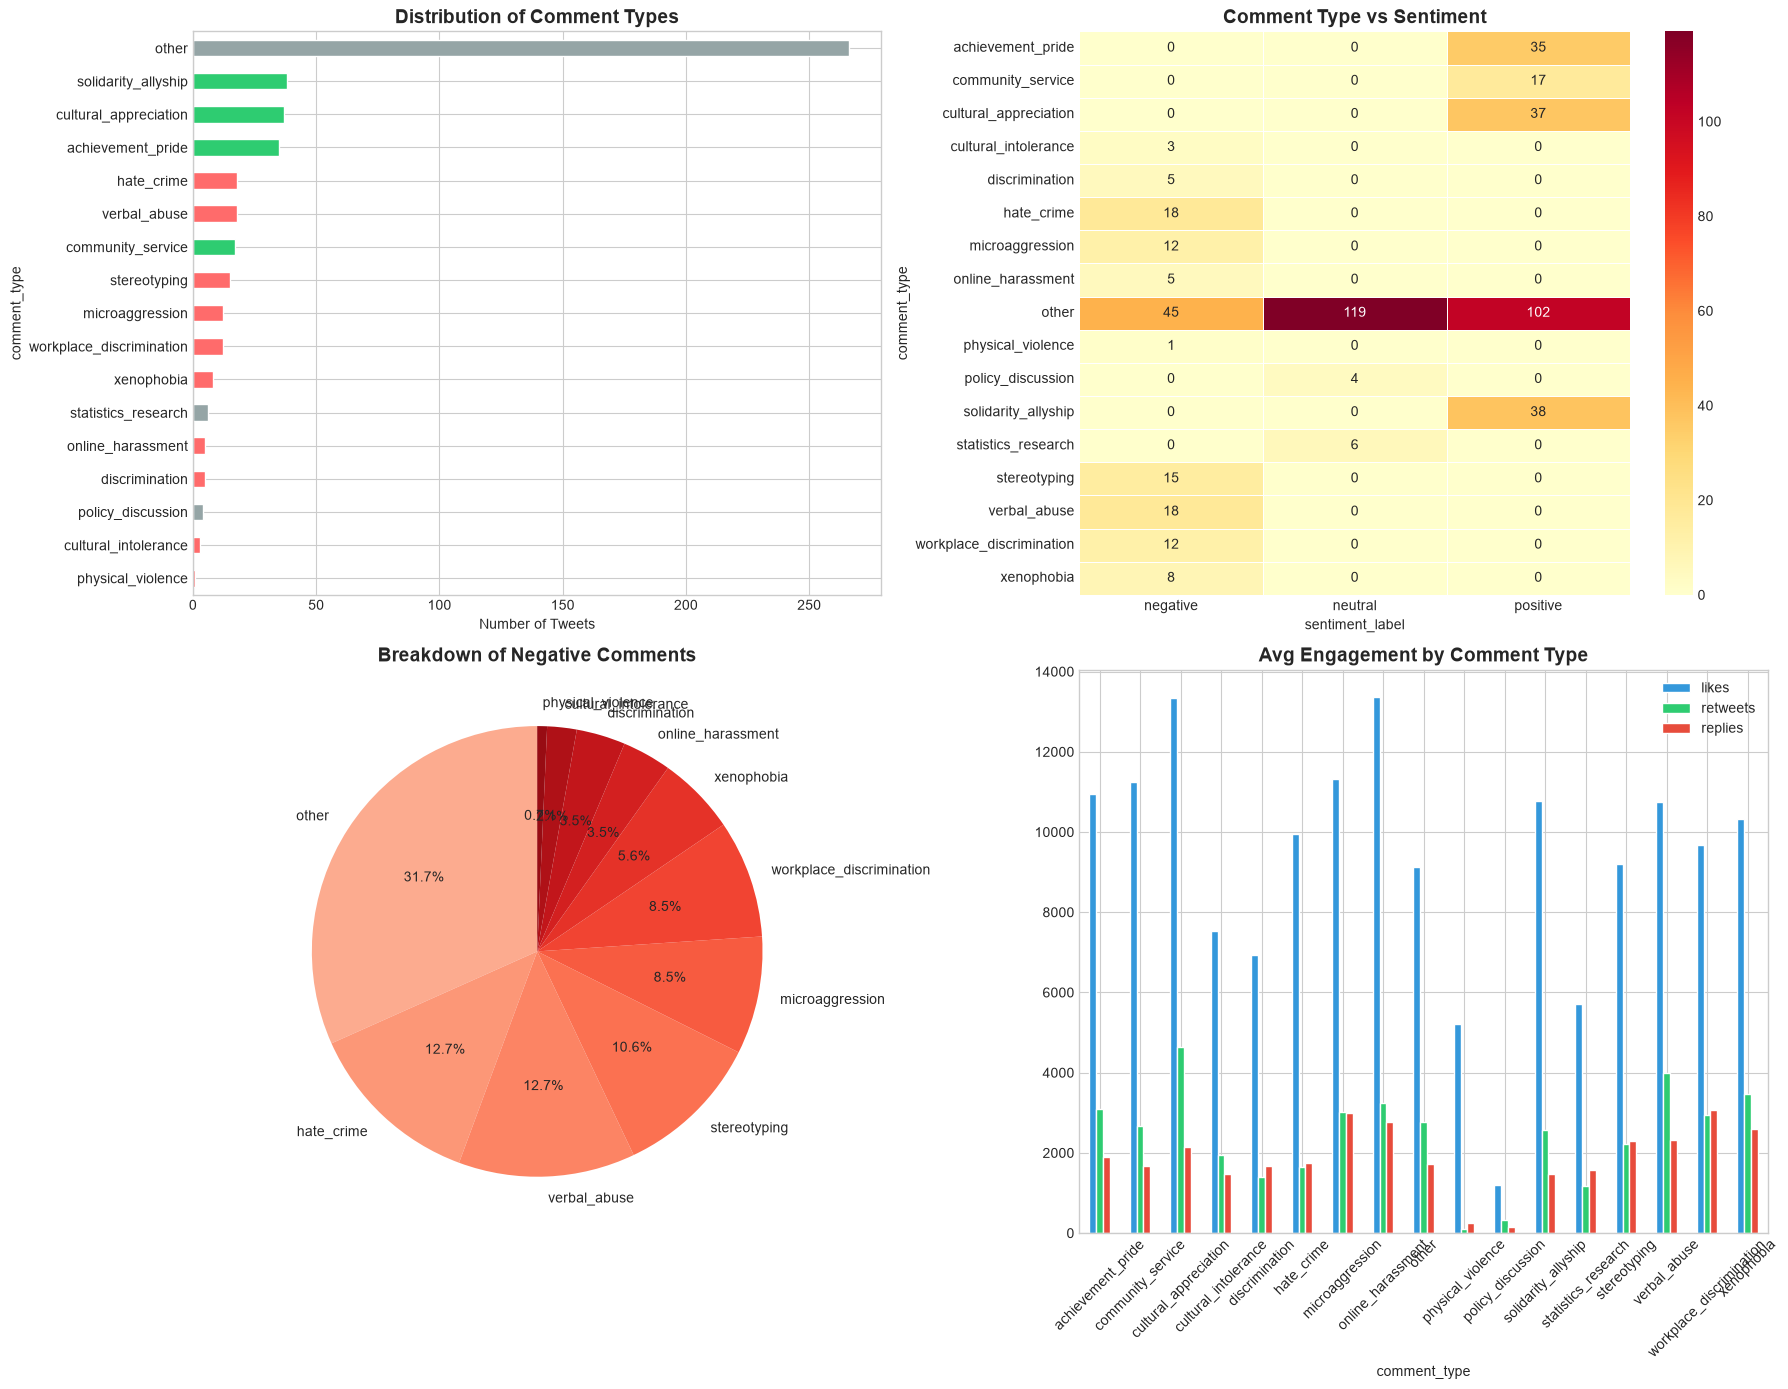

[SAVED] visualizations/phase2_comment_types.png


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Comment type distribution
type_counts = df['comment_type'].value_counts()
colors = []
for cat in type_counts.index:
    if cat in ['solidarity_allyship', 'cultural_appreciation', 'achievement_pride', 'community_service']:
        colors.append('#2ECC71')
    elif cat in ['statistics_research', 'policy_discussion', 'other']:
        colors.append('#95A5A6')
    else:
        colors.append('#FF6B6B')

type_counts.plot(kind='barh', ax=axes[0,0], color=colors, edgecolor='white')
axes[0,0].set_title('Distribution of Comment Types', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Number of Tweets')
axes[0,0].invert_yaxis()

# 2. Heatmap
ct = pd.crosstab(df['comment_type'], df['sentiment_label'])
sns.heatmap(ct, annot=True, fmt='d', cmap='YlOrRd', ax=axes[0,1],
            linewidths=0.5, linecolor='white')
axes[0,1].set_title('Comment Type vs Sentiment', fontsize=14, fontweight='bold')

# 3. Negative breakdown
neg_types = df[df['sentiment_label'] == 'negative']['comment_type'].value_counts()
if len(neg_types) > 0:
    neg_types.plot(kind='pie', ax=axes[1,0], autopct='%1.1f%%',
                   colors=plt.cm.Reds(np.linspace(0.3, 0.9, len(neg_types))), startangle=90)
    axes[1,0].set_title('Breakdown of Negative Comments', fontsize=14, fontweight='bold')
    axes[1,0].set_ylabel('')

# 4. Engagement by type
eng = df.groupby('comment_type')[['likes', 'retweets', 'replies']].mean()
eng.plot(kind='bar', ax=axes[1,1], color=['#3498DB', '#2ECC71', '#E74C3C'], edgecolor='white')
axes[1,1].set_title('Avg Engagement by Comment Type', fontsize=14, fontweight='bold')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('visualizations/phase2_comment_types.png', dpi=150, bbox_inches='tight')
plt.show()
print("[SAVED] visualizations/phase2_comment_types.png")

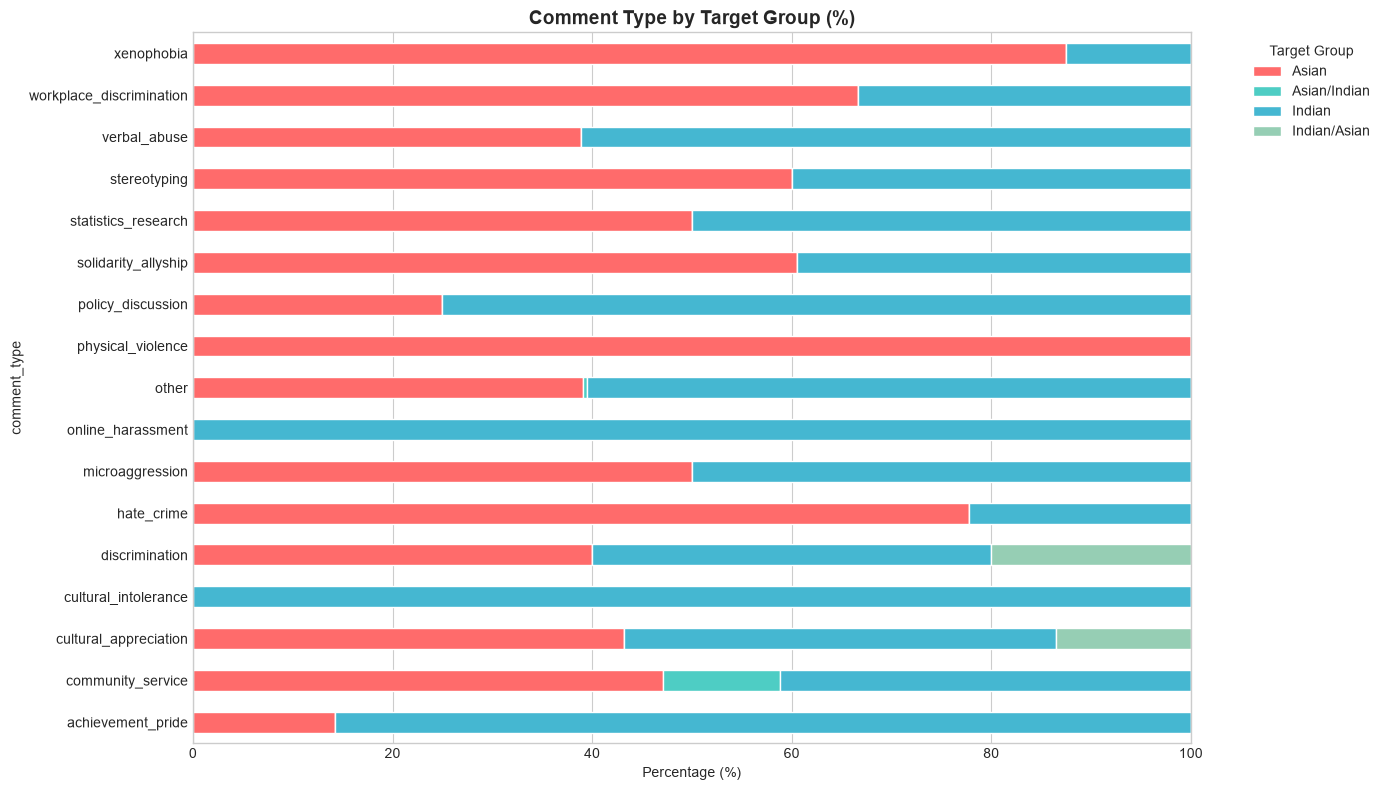

[SAVED] visualizations/phase2_type_by_target.png


In [6]:
# Cross-tab by target group
fig, ax = plt.subplots(figsize=(14, 8))
ct_norm = pd.crosstab(df['comment_type'], df['target_group'], normalize='index') * 100
ct_norm.plot(kind='barh', stacked=True, ax=ax,
             color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'], edgecolor='white')
ax.set_title('Comment Type by Target Group (%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Percentage (%)')
ax.legend(title='Target Group', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.savefig('visualizations/phase2_type_by_target.png', dpi=150, bbox_inches='tight')
plt.show()
print("[SAVED] visualizations/phase2_type_by_target.png")

## 2.7 Save Phase 2 Output

In [7]:
df.to_csv('data/phase2_categorized.csv', index=False)

print("[OK] Phase 2 complete!")
print(f"   Output: data/phase2_categorized.csv")
print(f"   Comment types: {df['comment_type'].nunique()}")
print(f"   Unclassified: {(df['comment_type']=='other').sum()}")

[OK] Phase 2 complete!
   Output: data/phase2_categorized.csv
   Comment types: 17
   Unclassified: 266


---
## Summary

**Phase 2** categorized 500 tweets into specific discourse types using keyword-based NLP classification.

The most common negative types include **stereotyping**, **workplace discrimination**, **xenophobia**, and **cultural intolerance** — reflecting the real-world landscape of racism experienced by Indian and Asian communities.

**Next: Phase 3** — Deep analytics (emotion detection, subjectivity, TF-IDF, word clouds, engagement analysis)